In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
pd.set_option("display.float_format", lambda x: "%.2f" % x)

# 1. Load Data
# Superstore files use Windows-1252/Latin-1 encoding
df = pd.read_csv("Superstore.csv", encoding="windows-1252")

print("Initial Dataset Shape:", df.shape)
print("Columns Loaded:", len(df.columns))

Initial Dataset Shape: (9994, 21)
Columns Loaded: 21


## 1. Data Cleaning, Validation & Feature Engineering
We validate data integrity by:
1. Checking for missing values and duplicate rows.
2. Parsing `Order Date` and `Ship Date` to `datetime` before performing chronological validations.
3. Ensuring shipping dates logically occur on or after order dates.
4. Engineering business-critical metrics: `Shipping Days`, `Order Month`, and transaction-level `Profit Margin %`.

In [2]:
# Check missing values & duplicates
print("Missing values total:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Unique Row IDs:", df["Row ID"].nunique())

# Convert dates FIRST before validation
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Chronological and range validation
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

invalid_shipping = (df["Ship Date"] < df["Order Date"]).sum()
print("Ship Date occurs before Order Date:", invalid_shipping)

print("Invalid discounts (<0 or >1):", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())
print("Non-positive sales records:", (df["Sales"] <= 0).sum())

# Feature Engineering
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Order Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Profit Margin %"] = (df["Profit"] / df["Sales"]) * 100

print("\nData Cleaning Complete. Sample transformed records:")
df[["Order ID", "Order Date", "Ship Date", "Shipping Days", "Sales", "Profit", "Profit Margin %"]].head()

Missing values total: 0
Duplicate rows: 0
Unique Row IDs: 9994
Invalid Order Dates: 0
Invalid Ship Dates: 0
Ship Date occurs before Order Date: 0
Invalid discounts (<0 or >1): 0
Non-positive sales records: 0

Data Cleaning Complete. Sample transformed records:


,Order ID,Order Date,Ship Date,Shipping Days,Sales,Profit,Profit Margin %
0,CA-2016-152156,2016-11-08,2016-11-11,3,261.96,41.91,16.00
1,CA-2016-152156,2016-11-08,2016-11-11,3,731.94,219.58,30.00
2,CA-2016-138688,2016-06-12,2016-06-16,4,14.62,6.87,47.00
3,US-2015-108966,2015-10-11,2015-10-18,7,957.58,-383.03,-40.00
4,US-2015-108966,2015-10-11,2015-10-18,7,22.37,2.52,11.25


### Data Quality Findings
- **Completeness:** The dataset contains 9,994 transaction records across 21 columns with **zero null values** and **zero duplicate rows**.
- **Validity:** Following datetime conversion, 100% of shipping dates occur on or after their corresponding order dates (`invalid_shipping = 0`). All sales figures are positive and discounts fall strictly within the valid range of `[0.0, 0.8]`.

## 2. Executive Business KPIs
We compute baseline operational metrics across the full multi-year period to establish baseline sales volume, profit, aggregate margin, and order economics.

In [3]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
overall_margin = (total_profit / total_sales) * 100
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
avg_order_value = df.groupby("Order ID")["Sales"].sum().mean()
avg_shipping_time = df["Shipping Days"].mean()

print("=" * 50)
print("              BUSINESS EXECUTIVE KPIs            ")
print("=" * 50)
print(f"Total Gross Sales        : ${total_sales:,.2f}")
print(f"Total Net Profit         : ${total_profit:,.2f}")
print(f"Overall Profit Margin    : {overall_margin:.2f}%")
print(f"Total Distinct Orders    : {total_orders:,}")
print(f"Total Unique Customers   : {total_customers:,}")
print(f"Average Order Value (AOV): ${avg_order_value:,.2f}")
print(f"Average Shipping Time    : {avg_shipping_time:.1f} days")
print("=" * 50)

              BUSINESS EXECUTIVE KPIs            
Total Gross Sales        : $2,297,200.86
Total Net Profit         : $286,397.02
Overall Profit Margin    : 12.47%
Total Distinct Orders    : 5,009
Total Unique Customers   : 793
Average Order Value (AOV): $458.61
Average Shipping Time    : 4.0 days


## 3. Monthly Sales and Profit Trend Analysis
Evaluating performance trends across monthly intervals to analyze revenue growth and identify any divergence between revenue and profitability.

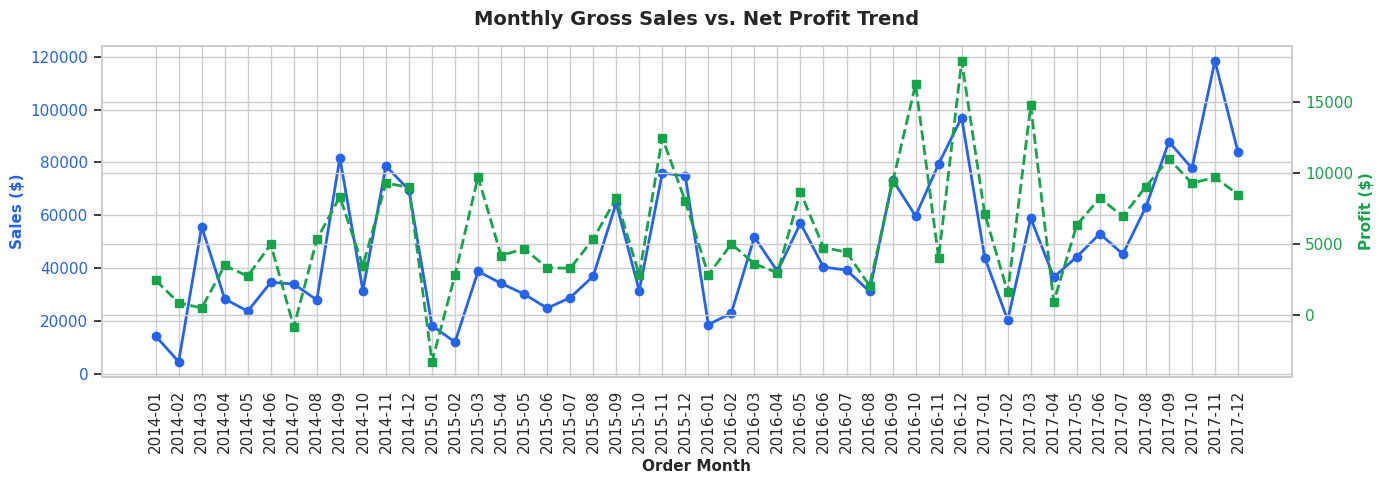

In [4]:
monthly_perf = (
    df.groupby("Order Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(14, 5))

# Plot Sales on Primary Y-Axis
ax1.plot(
    monthly_perf["Order Month"],
    monthly_perf["Total_Sales"],
    color="#2563EB",
    marker="o",
    linewidth=2,
    label="Gross Sales"
)
ax1.set_xlabel("Order Month", fontsize=11, fontweight="bold")
ax1.set_ylabel("Sales ($)", color="#2563EB", fontsize=11, fontweight="bold")
ax1.tick_params(axis="y", labelcolor="#2563EB")
ax1.tick_params(axis="x", rotation=90)

# Plot Profit on Secondary Y-Axis to account for scale differences
ax2 = ax1.twinx()
ax2.plot(
    monthly_perf["Order Month"],
    monthly_perf["Total_Profit"],
    color="#16A34A",
    marker="s",
    linewidth=2,
    linestyle="--",
    label="Net Profit"
)
ax2.set_ylabel("Profit ($)", color="#16A34A", fontsize=11, fontweight="bold")
ax2.tick_params(axis="y", labelcolor="#16A34A")

plt.title("Monthly Gross Sales vs. Net Profit Trend", fontsize=14, fontweight="bold", pad=15)
fig.tight_layout()
plt.savefig("1_monthly_trend.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:** Both sales and profits display recurring seasonal spikes towards Q4 (September through December), consistent with annual holiday retail cycles. However, profit spikes are proportionally flatter than sales volume spikes during peak discount periods, indicating potential margin compression during high-volume sales events.

## 4. Profitability by Sub-Category (Identifying Loss-Makers)
We isolate total profit contributions across all 17 sub-categories to identify which lines drive the bottom line and which generate operational losses.

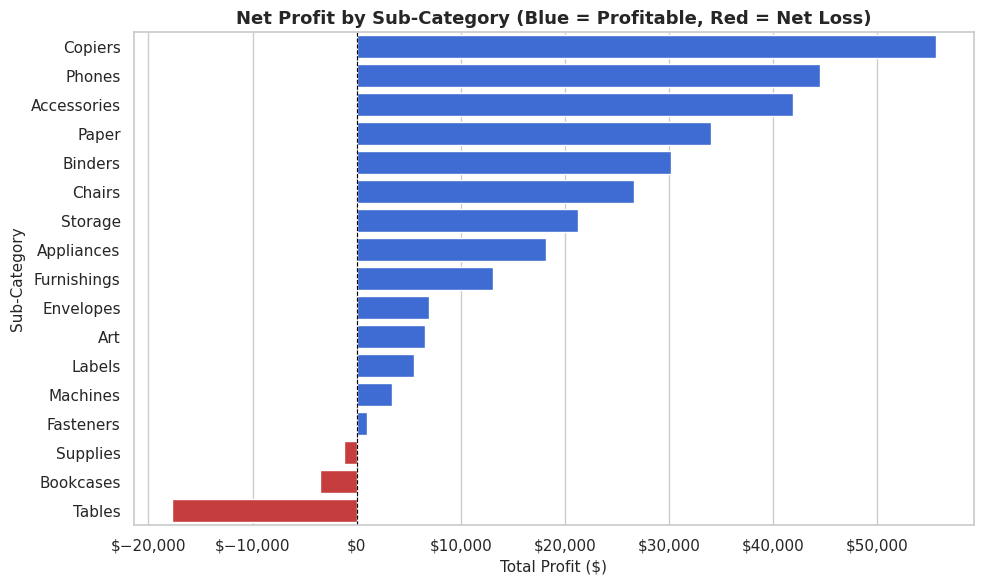

Bottom 3 Loss-Generating Sub-Categories:
Sub-Category     Sales    Profit
    Supplies  46673.54  -1189.10
   Bookcases 114880.00  -3472.56
      Tables 206965.53 -17725.48


In [5]:
subcat_perf = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .sort_values(by="Profit", ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 6))
colors = ["#2563EB" if p >= 0 else "#DC2626" for p in subcat_perf["Profit"]]

# Fixed Seaborn warning using hue and legend=False
ax = sns.barplot(
    data=subcat_perf,
    y="Sub-Category",
    x="Profit",
    hue="Sub-Category",
    palette=colors,
    legend=False
)

plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Net Profit by Sub-Category (Blue = Profitable, Red = Net Loss)", fontsize=13, weight="bold")
plt.xlabel("Total Profit ($)", fontsize=11)
plt.ylabel("Sub-Category", fontsize=11)

# Format X axis with commas
ax.xaxis.set_major_formatter("${x:,.0f}")
plt.tight_layout()
plt.savefig("2_profit_by_subcategory.png", dpi=300, bbox_inches="tight")
plt.show()

print("Bottom 3 Loss-Generating Sub-Categories:")
print(subcat_perf.tail(3).to_string(index=False))

**Insight:** While technology and office supply items like Copiers ($55.6K profit), Phones ($44.5K), and Accessories ($41.9K) drive substantial profit, three sub-categories operate at a cumulative net loss:


- **Tables:** -$17,725.48
- **Bookcases:** -$3,472.56
- **Supplies:** -$1,189.10

This proves that top-line revenue is being eroded by specific product lines, warranting a closer look at regional logistics, pricing, and discounting strategies.

## 5. Discount and Profitability Analysis (Association Analysis)
We investigate the relationship between discounting tiers and aggregate profit margins overall, across categories, and across sub-categories. 

*Note: This is an observational association analysis and does not imply direct standalone causation, as product cost structure, regional shipping, and volume mix also influence margins.

OVERALL PROFITABILITY BY DISCOUNT TIER:
  Discount Tier  Orders  Transactions      Sales    Profit  Profit Margin %
0            0%    2644          4798 1087908.47 320987.60            29.51
1         1-20%    2507          3803  846522.24 100785.47            11.91
2        21-40%     400           460  234137.90 -35817.47           -15.30
3        41-60%     195           215   71048.21 -28944.19           -40.74
4          61%+     594           718   57584.04 -70614.40          -122.63


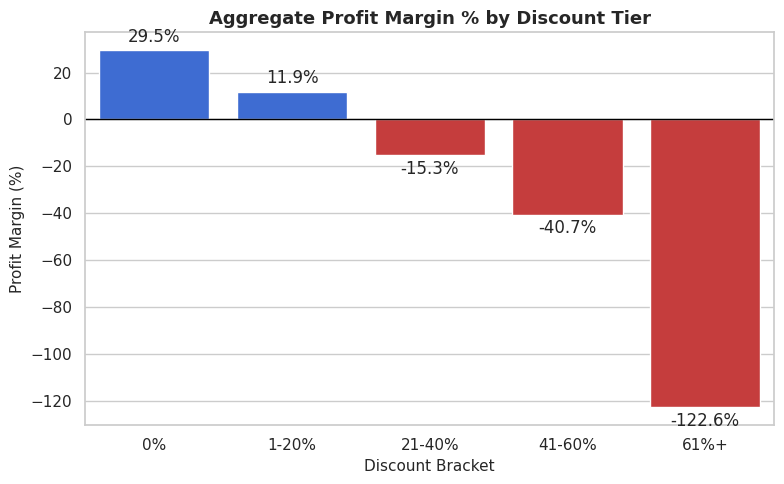

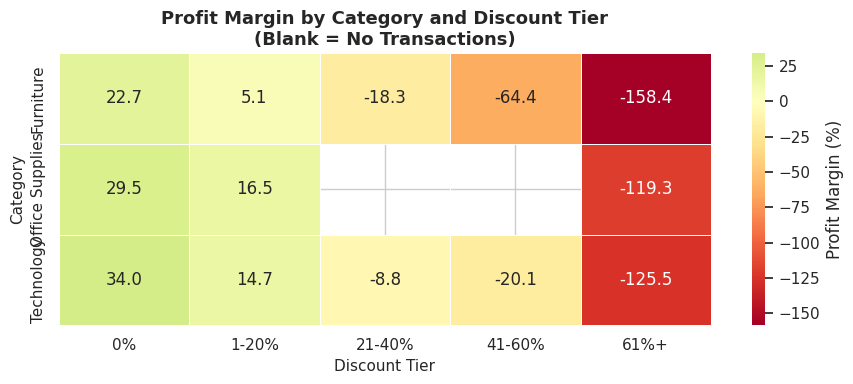

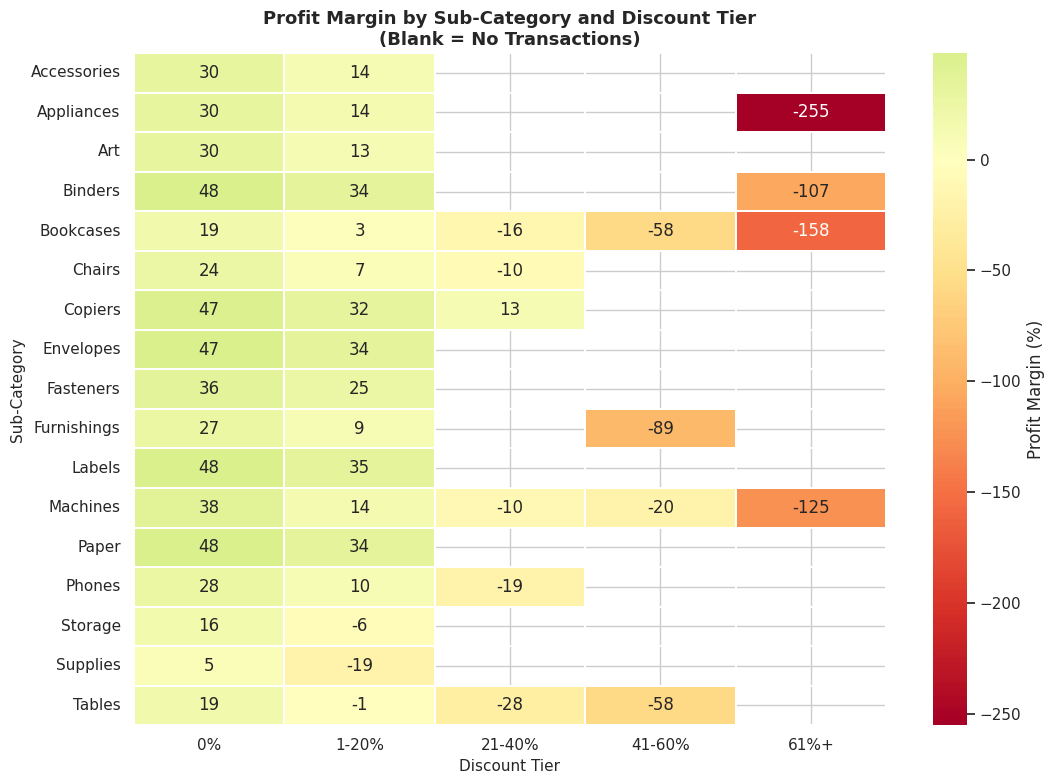

Transaction-level Pearson Correlation between Discount and Profit: -0.219


In [7]:
# Create standard discount bins
bins = [-0.001, 0, 0.20, 0.40, 0.60, 1.00]
labels = ["0%", "1-20%", "21-40%", "41-60%", "61%+"]
df["Discount Tier"] = pd.cut(df["Discount"], bins=bins, labels=labels, include_lowest=True)

# A. Aggregate Discount Summary
discount_summary = (
    df.groupby("Discount Tier", observed=True)
    .agg(
        Orders=("Order ID", "nunique"),
        Transactions=("Row ID", "count"),
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Avg_Discount=("Discount", "mean")
    )
    .reset_index()
)
discount_summary["Profit Margin %"] = (discount_summary["Profit"] / discount_summary["Sales"]) * 100

print("OVERALL PROFITABILITY BY DISCOUNT TIER:")
print(discount_summary[["Discount Tier", "Orders", "Transactions", "Sales", "Profit", "Profit Margin %"]].round(2))

# B. Visualization of Profit Margins across Discount Tiers
plt.figure(figsize=(8, 5))
colors = ["#2563EB" if val >= 0 else "#DC2626" for val in discount_summary["Profit Margin %"]]

ax = sns.barplot(
    data=discount_summary,
    x="Discount Tier",
    y="Profit Margin %",
    hue="Discount Tier",
    palette=colors,
    legend=False
)
plt.axhline(0, color="black", linewidth=1)
plt.title("Aggregate Profit Margin % by Discount Tier", fontsize=13, weight="bold")
plt.xlabel("Discount Bracket", fontsize=11)
plt.ylabel("Profit Margin (%)", fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig("3_discount_profitability.png", dpi=300, bbox_inches="tight")
plt.show()

# C. Category x Discount Tier Heatmap
category_discount = (
    df.groupby(["Category", "Discount Tier"], observed=True)
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .reset_index()
)
category_discount["Profit Margin %"] = np.where(
    category_discount["Sales"] != 0,
    (category_discount["Profit"] / category_discount["Sales"]) * 100,
    np.nan
)

heatmap_cat = category_discount.pivot(index="Category", columns="Discount Tier", values="Profit Margin %")

plt.figure(figsize=(9, 4))
sns.heatmap(heatmap_cat, annot=True, fmt=".1f", cmap="RdYlGn", center=0, linewidths=0.5, cbar_kws={"label": "Profit Margin (%)"})
plt.title("Profit Margin by Category and Discount Tier\n(Blank = No Transactions)", fontsize=13, weight="bold")
plt.xlabel("Discount Tier", fontsize=11)
plt.ylabel("Category", fontsize=11)
plt.tight_layout()
plt.savefig("4_category_discount_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# D. Sub-Category x Discount Tier Heatmap
subcat_discount = (
    df.groupby(["Sub-Category", "Discount Tier"], observed=True)
    .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
    .reset_index()
)
subcat_discount["Profit Margin %"] = np.where(
    subcat_discount["Sales"] != 0,
    (subcat_discount["Profit"] / subcat_discount["Sales"]) * 100,
    np.nan
)

heatmap_sub = subcat_discount.pivot(index="Sub-Category", columns="Discount Tier", values="Profit Margin %")

plt.figure(figsize=(11, 8))
sns.heatmap(heatmap_sub, annot=True, fmt=".0f", cmap="RdYlGn", center=0, linewidths=0.3, cbar_kws={"label": "Profit Margin (%)"})
plt.title("Profit Margin by Sub-Category and Discount Tier\n(Blank = No Transactions)", fontsize=13, weight="bold")
plt.xlabel("Discount Tier", fontsize=11)
plt.ylabel("Sub-Category", fontsize=11)
plt.tight_layout()
plt.savefig("5_subcategory_discount_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

corr = df["Discount"].corr(df["Profit"])
print(f"Transaction-level Pearson Correlation between Discount and Profit: {corr:.3f}")

**Insight:** 
- Transactions with **no discount** achieved a healthy **+29.51% aggregate profit margin**, while the **1–20% discount tier** yielded **+11.91%**.
- However, transactions discounted **above 20%** operated at steep aggregate losses: **-15.30%** (21–40% tier), **-40.74%** (41–60% tier), and **-122.63%** (61%+ tier).
- The Category and Sub-Category heatmaps confirm this is not merely a product mix issue: margins for Furniture drop from **+22.7%** at 0% discount down to **-18.3%** at 21–40% discount, and Tables experience negative margins across all non-zero discount tiers.
- **Analytical Caution:** While transaction-level correlation is weak-to-moderate negative ($r = -0.219$), the data clearly demonstrates an association between aggressive discounting and bottom-line profit erosion.

## 6. Customer RFM Segmentation
Using **Recency** (days since last purchase), **Frequency** (distinct order count), and **Monetary Value** (total historical spend), we score each customer from 1 to 4 across all three dimensions and assign them into 6 strategic behavioral segments.

RFM CUSTOMER SEGMENTATION SUMMARY:
    RFM Segment  Customers  Avg_Recency  Avg_Frequency  Avg_Monetary  Total_Revenue  Customer %  Revenue %
      Champions        176        33.23           8.81       4562.13      802935.47       22.19      34.95
        At Risk        107       170.62           8.31       4959.72      530689.63       13.49      23.10
      Promising        159        34.96           4.52       2247.42      357340.16       20.05      15.56
Needs Attention        110       253.31           6.08       2959.98      325597.70       13.87      14.17
    Hibernating        179       322.64           3.92       1015.32      181741.61       22.57       7.91
 Loyal / Active         62        31.06           7.77       1595.10       98896.29        7.82       4.31


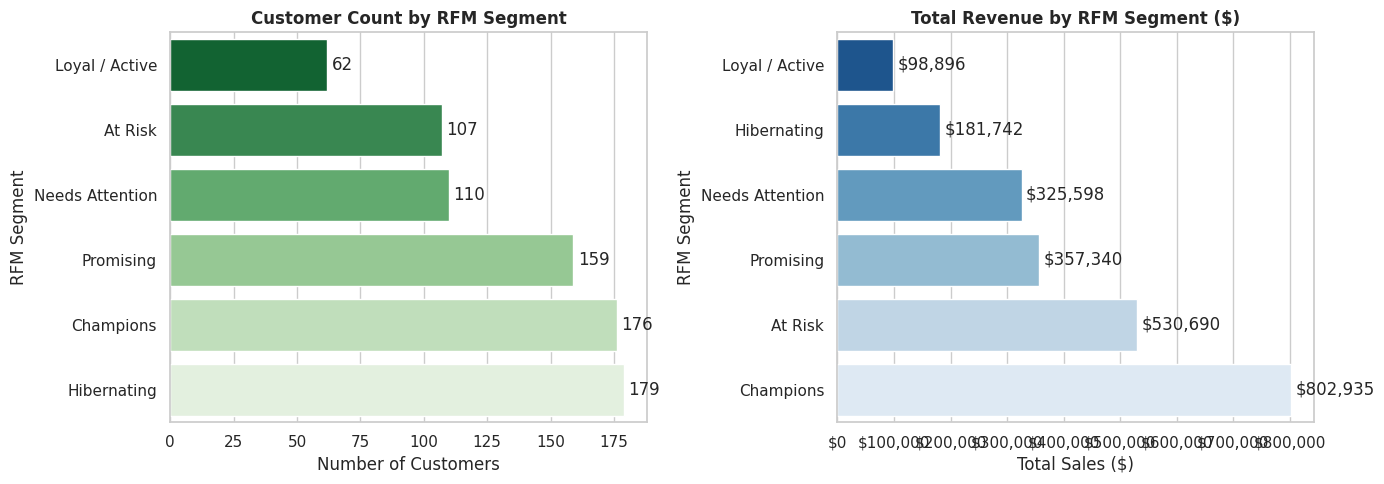

In [8]:
snapshot_date = df["Order Date"].max() + pd.Timedelta(days=1)

# A. Calculate Customer-Level RFM Metrics
rfm = (
    df.groupby("Customer ID")
    .agg(
        Customer_Name=("Customer Name", "first"),
        Recency=("Order Date", lambda x: (snapshot_date - x.max()).days),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

# B. Quartile Scoring (1 to 4)
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), q=4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), q=4, labels=[1, 2, 3, 4]).astype(int)

rfm["RFM_Code"] = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)
rfm["RFM_Total"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

# C. Define Rule-Based Segments Incorporating R, F, and M
def assign_rfm_segment(row):
    R, F, M = row["R_Score"], row["F_Score"], row["M_Score"]
    
    # Active, frequent, high spenders
    if R >= 3 and F >= 3 and M >= 3:
        return "Champions"
    # High historical value and frequency, but lapsing recency
    elif R <= 2 and F >= 3 and M >= 3:
        return "At Risk"
    # Recent customers with moderate frequency
    elif R >= 3 and F <= 2:
        return "Promising"
    # Consistently active customers with moderate spend
    elif R >= 3:
        return "Loyal / Active"
    # Lowest engagement and spend across the board
    elif R <= 2 and F <= 2 and M <= 2:
        return "Hibernating"
    # Intermediate customers
    else:
        return "Needs Attention"

rfm["RFM Segment"] = rfm.apply(assign_rfm_segment, axis=1)

# D. Segment Summary
segment_summary = (
    rfm.groupby("RFM Segment")
    .agg(
        Customers=("Customer ID", "nunique"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .reset_index()
)

segment_summary["Customer %"] = (segment_summary["Customers"] / rfm["Customer ID"].nunique()) * 100
segment_summary["Revenue %"] = (segment_summary["Total_Revenue"] / rfm["Monetary"].sum()) * 100
segment_summary = segment_summary.sort_values(by="Total_Revenue", ascending=False)

print("RFM CUSTOMER SEGMENTATION SUMMARY:")
print(segment_summary.round(2).to_string(index=False))

# E. Visualizations
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Customer Count by Segment
sns.barplot(
    data=segment_summary.sort_values("Customers", ascending=True),
    x="Customers",
    y="RFM Segment",
    palette="Greens_r",
    ax=ax1,
    hue="RFM Segment",
    legend=False
)
ax1.set_title("Customer Count by RFM Segment", fontsize=12, weight="bold")
ax1.set_xlabel("Number of Customers")
for container in ax1.containers:
    ax1.bar_label(container, padding=3)

# Plot 2: Total Revenue Contribution by Segment
sns.barplot(
    data=segment_summary.sort_values("Total_Revenue", ascending=True),
    x="Total_Revenue",
    y="RFM Segment",
    palette="Blues_r",
    ax=ax2,
    hue="RFM Segment",
    legend=False
)
ax2.set_title("Total Revenue by RFM Segment ($)", fontsize=12, weight="bold")
ax2.set_xlabel("Total Sales ($)")
ax2.xaxis.set_major_formatter("${x:,.0f}")
for container in ax2.containers:
    ax2.bar_label(container, fmt="${:,.0f}", padding=3)

plt.tight_layout()
plt.savefig("6_rfm_analysis.png", dpi=300, bbox_inches="tight")
plt.show()

**Insight:**
- **Champions:** Represent **22.19% of the customer base** (176 customers) but account for **34.95% of total revenue** ($802.9K), with an average historical spend of $4,562.13 and high purchase recency (33.2 days).
- **At-Risk Cohort:** Represent only **13.49% of customers** (107 customers) yet account for **23.10% of revenue** ($530.7K) with an average historical spend of $4,959.72. Because their average recency has lapsed to 170.6 days, they represent the highest financial priority for automated win-back retention marketing.
- **Hibernating:** Make up **22.57% of customers** but contribute only **7.91% of revenue**. Broad promotional spending on this group should be deprioritized in favor of nurturing the Promising cohort.

## 7. Clean Export for Power BI Reporting
We merge the RFM segmentation labels back to the transaction table and export an enriched, clean CSV for business intelligence reporting.

In [9]:
# Merge only necessary RFM metrics to avoid duplicated columns
df_export = df.merge(
    rfm[["Customer ID", "Recency", "Frequency", "Monetary", "RFM Segment"]],
    on="Customer ID",
    how="left"
)

# Export clean dataset
output_filename = "Cleaned_Superstore_for_PowerBI.csv"
df_export.to_csv(output_filename, index=False)

print(f"[SUCCESS] Enriched dataset exported successfully as '{output_filename}'")
print("Final Exported Shape:", df_export.shape)
print("Columns included in export:\n", df_export.columns.tolist())

[SUCCESS] Enriched dataset exported successfully as 'Cleaned_Superstore_for_PowerBI.csv'
Final Exported Shape: (9994, 29)
Columns included in export:
 ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Days', 'Order Month', 'Profit Margin %', 'Discount Tier', 'Recency', 'Frequency', 'Monetary', 'RFM Segment']
